In [1]:
from typing import cast

# pytorch
import torch
from torch_geometric.utils import degree, homophily
from torch_geometric.data import Data
from dataset import CLASS_NAMES, add_stratified_masks, load_facebook_data

# plotting
from matplotlib import pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

## Multi-Layer GNN for Facebook Page Classification
### COMP3710 Working Prototype Project in the Era of Artificial Intelligence
#### Derek McKinney (dm-uq)
#### SN: 45506053

### Data Pipeline
<br>
References:

Facebook Page-Page dataset:
    https://github.com/gayanku/facebook_page-page_dataset

PyG FacebookPagePage:
    https://pytorch-geometric.readthedocs.io/en/latest/generated/torch_geometric.datasets.FacebookPagePage.html

Constants

In [2]:
# plot styling
sns.set_theme(
    context="notebook",
    style="whitegrid",
)

#### Data Inspection

In [3]:
# load the FacebookPagePage dataset
dataset = load_facebook_data()

# inspect data properties
print(f'Dataset: {dataset}')
print(f'Number of graphs: {len(dataset)}')
print(f'Number of features: {dataset.num_features}')
print(f'Number of classes: {dataset.num_classes}')

data = dataset[0]  # get first graph object

print('\nGraph data format:')
print(data)

Dataset: FacebookPagePage()
Number of graphs: 1
Number of features: 128
Number of classes: 4

Graph data format:
Data(x=[22470, 128], edge_index=[2, 342004], y=[22470])


Basic EDA

In [4]:
# inspect data class counts/proportions
classes, counts = torch.unique(data.y, return_counts=True)

label_count = counts.sum().item()
node_count: int | None = data.num_nodes

if node_count is None:
    raise ValueError("Graph does not define the number of nodes.")
print(f'\nNum missing labels: {node_count - label_count}\n')

print('Class distribution:')
for cls, count in zip(classes.tolist(), counts.tolist()):
    print(
        f"  {CLASS_NAMES[cls]:10}: "
        f"{count:5} "
        f"({count / node_count:.2%})"
    )


Num missing labels: 0

Class distribution:
  tvshow    :  6495 (28.91%)
  government:  6880 (30.62%)
  company   :  5768 (25.67%)
  politician:  3327 (14.81%)


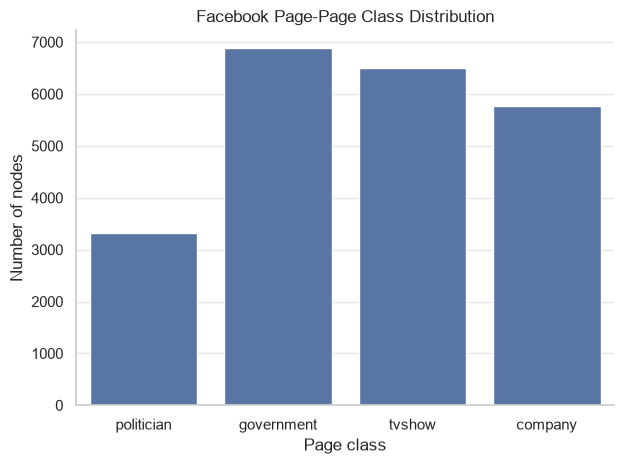

In [5]:
# plot data class counts
class_labels = [
    CLASS_NAMES[label]
    for label in data.y.tolist()
]

fig_class_counts, ax_class_counts = plt.subplots()

sns.countplot(
    x=class_labels,
    ax=ax_class_counts,
)

ax_class_counts.set(
    xlabel="Page class",
    ylabel="Number of nodes",
    title="Facebook Page-Page Class Distribution",
)

sns.despine(ax=ax_class_counts)
fig_class_counts.tight_layout()

plt.show()

In [8]:
# save class counts plot
fig_class_counts.savefig(
    "images/data-pipeline/class_counts_initial.png",
    dpi=200,
    bbox_inches="tight",
)

In [9]:
# inspect data node degrees
deg = degree(
    data.edge_index[0],
    num_nodes=data.num_nodes,
)

print()
print(f"Degree min:    {deg.min().item():.0f}")
print(f"Degree median: {deg.median().item():.0f}")
print(f"Degree mean:   {deg.mean().item():.2f}")
print(f"Degree max:    {deg.max().item():.0f}")




Degree min:    1
Degree median: 7
Degree mean:   15.22
Degree max:    709


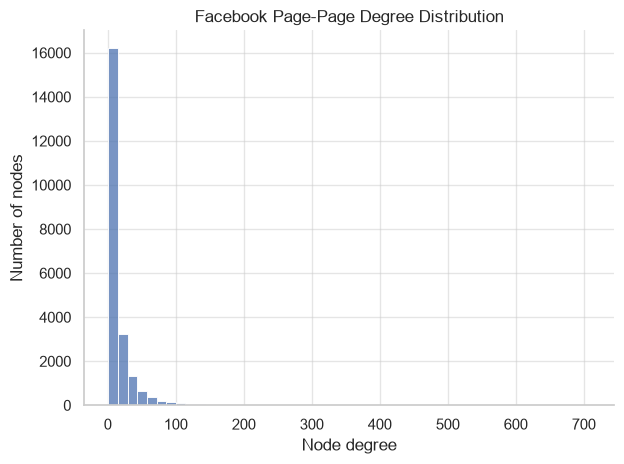

In [10]:
# plot data node degree counts
fig_degree, ax_degree = plt.subplots()

sns.histplot(
    x=deg.cpu().numpy(),
    bins=50,
    ax=ax_degree,
)

ax_degree.set(
    xlabel="Node degree",
    ylabel="Number of nodes",
    title="Facebook Page-Page Degree Distribution",
)

sns.despine(ax=ax_degree)
fig_degree.tight_layout()

plt.show()

In [11]:
# save node degree counts plot
fig_degree.savefig(
    "images/data-pipeline/node_degrees_initial.png",
    dpi=200,
    bbox_inches="tight",
)

In [12]:
# inspect features
print()
print(f"Feature min:   {data.x.min().item():.4f}")
print(f"Feature max:   {data.x.max().item():.4f}")
print(f"Feature mean:  {data.x.mean().item():.4f}")
print(f"Feature std:   {data.x.std().item():.4f}")
print(f"Zero fraction: {(data.x == 0).float().mean().item():.4f}")


Feature min:   -2.0376
Feature max:   3.0020
Feature mean:  0.0103
Feature std:   0.2551
Zero fraction: 0.0000


In [13]:
# inspect graph structure
print()
print(f'Has isolated nodes: {data.has_isolated_nodes()}')
print(f'Has self-loops: {data.has_self_loops()}')
print(f'Is undirected: {data.is_undirected()}')


Has isolated nodes: False
Has self-loops: True
Is undirected: True


In [14]:
# inspect homophily (i.e. how likely nodes with the same label are near each other in a graph)
print()
print(
    f"Edge homophily: "
    f"{homophily(data.edge_index, data.y, method='edge'):.4f}"
)


Edge homophily: 0.8854


#### Data Splits

Provisional Data Splits for Feasibility Review

In [15]:
# create reproducible stratified train/validation/test splits
data = add_stratified_masks(
    cast(Data, data),
    train_pct=60,
    val_pct=20,
    test_pct=20,
    seed=808,
)

# verify the split masks are non-overlapping
assert not (data.train_mask & data.val_mask).any().item()
assert not (data.train_mask & data.test_mask).any().item()
assert not (data.val_mask & data.test_mask).any().item()
# verify the split masks cover the complete data set
assert (data.train_mask | data.val_mask | data.test_mask).all().item()

Inspect split sizes and class distributions

In [19]:
# inspect data splits class counts/proportions
labels = data.y
if not isinstance(labels, torch.Tensor):
    raise TypeError("Graph labels must be stored as a PyTorch Tensor.")

splits = {
    "Train": data.train_mask,
    "Validation": data.val_mask,
    "Test": data.test_mask,
}

# collect split/class values for the grouped proportion plot
split_names = []
split_class_names = []
split_proportions = []

for split_name, mask in splits.items():
    split_size = mask.sum().item()  # total size of given split

    # get label distribution for split
    classes, counts = torch.unique(
        labels[mask],
        return_counts=True,
    )

    # print the distribution of classes in this split
    print(f"\n{split_name}: {split_size} nodes")

    for cls, count in zip(
        classes.tolist(),
        counts.tolist(),
    ):
        # use within-split proportions for comparison
        proportion = count / split_size

        print(
            f"  {CLASS_NAMES[cls]:10}: "
            f"{count:5} "
            f"({proportion:.2%})"
        )

        split_names.append(split_name)
        split_class_names.append(CLASS_NAMES[cls])
        split_proportions.append(proportion)


Train: 13482 nodes
  tvshow    :  3897 (28.91%)
  government:  4128 (30.62%)
  company   :  3461 (25.67%)
  politician:  1996 (14.80%)

Validation: 4494 nodes
  tvshow    :  1299 (28.91%)
  government:  1376 (30.62%)
  company   :  1153 (25.66%)
  politician:   666 (14.82%)

Test: 4494 nodes
  tvshow    :  1299 (28.91%)
  government:  1376 (30.62%)
  company   :  1154 (25.68%)
  politician:   665 (14.80%)


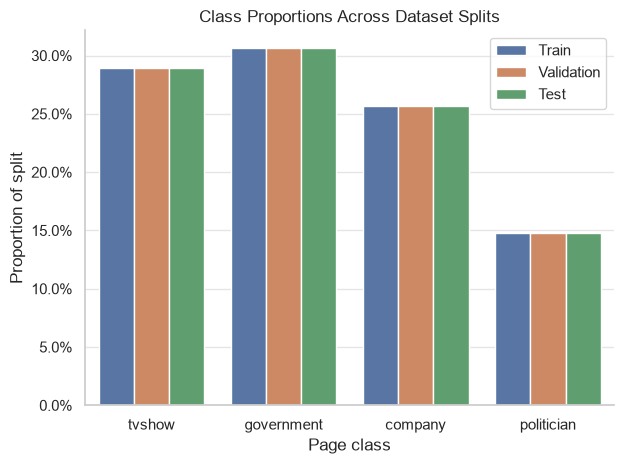

In [17]:
# plot data splits class proportions
fig_split_classes, ax_split_classes = plt.subplots()

sns.barplot(
    x=split_class_names,
    y=split_proportions,
    hue=split_names,
    ax=ax_split_classes,
)

ax_split_classes.set(
    xlabel="Page class",
    ylabel="Proportion of split",
    title="Class Proportions Across Dataset Splits",
)

ax_split_classes.yaxis.set_major_formatter(
    mtick.PercentFormatter(1.0)
)

sns.despine(ax=ax_split_classes)
fig_split_classes.tight_layout()

plt.show()

In [18]:
# save data splits class proportions plot
fig_split_classes.savefig(
    "images/data-pipeline/data_splits_class_counts_initial.png",
    dpi=200,
    bbox_inches="tight",
)